# Ga for tuning the h-p

In this notebook I will tune the size and number of the hidden layers.

## The NN

In [1]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


In [2]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [3]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [4]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [5]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



In [6]:
# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [7]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


## The EA 

### Structures

In [8]:
class Individual:
    def __init__(self, gene, fitness=0.0):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.gene = gene
        self.solution = self.gene
        self.fitness = fitness
    
    def __repr__(self):
        return f"Gene: {self.gene}, Solution: {self.solution}, Fitness: {self.fitness}"

# Example usage:
individual1 = Individual(gene=[16,16])
individual2 = Individual(gene=[32,32])

print(f"Individual 1: {individual1}")
print(f"Individual 2: {individual2}")


Individual 1: Gene: [16, 16], Solution: [16, 16], Fitness: 0.0
Individual 2: Gene: [32, 32], Solution: [32, 32], Fitness: 0.0


### Initialization

In [9]:
def initialization(population_size=10, number_of_layers_interval=[1, 5], number_of_units_space=[16, 32, 64, 128, 256, 512]):
    genes = []
    
    for _ in range(population_size):
        num_layers = random.randint(number_of_layers_interval[0], number_of_layers_interval[1])
        gene = [random.choice(number_of_units_space) for _ in range(num_layers)]
        genes.append(gene)
    
    individuals = [Individual(gene=g) for g in genes]
    return individuals

# Example usage:
population_size = 5
population = initialization(population_size)

for individual in population:
    print(individual)

Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.0
Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 0.0
Gene: [32, 256, 32, 64, 32], Solution: [32, 256, 32, 64, 32], Fitness: 0.0
Gene: [256], Solution: [256], Fitness: 0.0
Gene: [256, 512, 256], Solution: [256, 512, 256], Fitness: 0.0


### Fitness assessment

In [10]:
def fitness_evaluation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False
        ):

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=individual.gene,
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
individual = population[0]
fitness = fitness_evaluation(
    individual,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=5)

print(f"Individual: {individual}")
print(f"Fitness of individual: {fitness}")

Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.0
Fitness of individual: 0.5731700904508854


In [11]:
# Assess population
def evaluate_population(
        population,
        training_data,
        validation_data,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False):
    
    for individual in population:
        individual.fitness = fitness_evaluation(
            individual,
            training_data,
            validation_data,
            num_epochs_per_evaluation,
            lr,
            input_size,
            output_size,
            activation_function,
            initialize_weights)
    

# Example usage:
evaluate_population(
    population,
    train_dataloader,
    validation_dataloader,
    num_epochs_per_evaluation=2) # 2 is just for testing if it works 

for individual in population:
    print(individual)

Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665
Gene: [32, 256, 32, 64, 32], Solution: [32, 256, 32, 64, 32], Fitness: 2.2206613611667714
Gene: [256], Solution: [256], Fitness: 0.643263727109483
Gene: [256, 512, 256], Solution: [256, 512, 256], Fitness: 0.7445029105911863


### Selection

In [12]:
def find_best_individual(population):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
best_individual = find_best_individual(population)
print(best_individual)

Gene: [256], Solution: [256], Fitness: 0.643263727109483


In [13]:
# Roulette wheel selection (pay attention that the gretaer the fitness, the lower the probability of selection)
def roulette_wheel_selection(population, best_individual, num_to_select):
    remaining_population = [ind for ind in population if ind != best_individual]

    # Invert fitness values for selection probability calculation
    max_fitness = max(ind.fitness for ind in remaining_population)
    selection_values = [max_fitness - ind.fitness for ind in remaining_population]

    # Normalize selection values to probabilities
    total_selection_value = sum(selection_values)
    selection_probs = [value / total_selection_value for value in selection_values]

    selected_indices = np.random.choice(len(remaining_population), size=num_to_select, replace=True, p=selection_probs)
    selected_individuals = [remaining_population[i] for i in selected_indices]
    
    return selected_individuals

# Example 
roulette_selected = roulette_wheel_selection(population, best_individual, 3)
for ind in roulette_selected:
    print(ind)

Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665
Gene: [256, 512, 256], Solution: [256, 512, 256], Fitness: 0.7445029105911863
Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665


### Evolutionary operators 

In [14]:
# Description:
# aaa|aa 
# bbb|bb
# --> aaa|bb, bbb|aa
def single_point_crossover(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    child_gene1 = gene1[:point] + gene2[point:]
    child_gene2 = gene2[:point] + gene1[point:]
    child1 = Individual(gene=child_gene1)
    child2 = Individual(gene=child_gene2)
    return child1, child2

# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = single_point_crossover(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"Offspring of deterministic CX: {offspring1}")
print(f"Offspring of stochastic CX: {offspring2}")

Parent 1: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Parent 2: Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665
Offspring of deterministic CX: Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 0.0
Offspring of stochastic CX: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.0


In [15]:
# Example:
# aaa|aa|a
# bbb|bb|b
# --> aaa|bb|a, bbb|aa|b
def two_point_crossover(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    if len(gene1) < 2 or len(gene2) < 2:
        return parent1, parent2  # No crossover if either parent has less than 2 layers
    point1 = random.randint(1, min(len(gene1), len(gene2)) - 2)
    point2 = random.randint(point1 + 1, min(len(gene1), len(gene2)) - 1)
    child_gene1 = gene1[:point1] + gene2[point1:point2] + gene1[point2:]
    child_gene2 = gene2[:point1] + gene1[point1:point2] + gene2[point2:]
    child1 = Individual(gene=child_gene1)
    child2 = Individual(gene=child_gene2)
    return child1, child2


# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = two_point_crossover(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"Offspring of deterministic CX: {offspring1}")
print(f"Offspring of stochastic CX: {offspring2}")

Parent 1: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Parent 2: Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665
Offspring of deterministic CX: Gene: [128, 16, 128, 256], Solution: [128, 16, 128, 256], Fitness: 0.0
Offspring of stochastic CX: Gene: [128, 64, 64, 64], Solution: [128, 64, 64, 64], Fitness: 0.0


In [16]:
# (I DO NOT LIKE IT)
# Random choice for each gene 
def uniform_crossover(parent1, parent2):
    gene1, gene2 = parent1.gene, parent2.gene
    child_gene1, child_gene2 = [], []
    for p1, p2 in zip(gene1, gene2):
        if random.random() > 0.5:
            child_gene1.append(p1)
            child_gene2.append(p2)
        else:
            child_gene1.append(p2)
            child_gene2.append(p1)
    child1 = Individual(gene=child_gene1)
    child2 = Individual(gene=child_gene2)
    return child1, child2


# Exmaple usage
parent1 = population[0]
parent2 = population[1]
offspring1, offspring2 = uniform_crossover(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"Offspring of deterministic CX: {offspring1}")
print(f"Offspring of stochastic CX: {offspring2}")

Parent 1: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Parent 2: Gene: [128, 64, 128, 64], Solution: [128, 64, 128, 64], Fitness: 1.151250344641665
Offspring of deterministic CX: Gene: [128, 16, 64, 64], Solution: [128, 16, 64, 64], Fitness: 0.0
Offspring of stochastic CX: Gene: [128, 64, 128, 256], Solution: [128, 64, 128, 256], Fitness: 0.0


In [17]:
# Mutation
def random_resetting_mutation(individual, number_of_units_space=[16, 32, 64, 128, 256, 512]):
    mutated_gene = individual.gene.copy()
    index = random.randint(0, len(mutated_gene) - 1)
    mutated_gene[index] = random.choice(number_of_units_space)
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
mutated_individual = random_resetting_mutation(individual)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Mutated individual: Gene: [64, 16, 64, 256], Solution: [64, 16, 64, 256], Fitness: 0.0


In [18]:
# This mutation was mine, i think it is smart
def increment_decrement_mutation(individual, number_of_units_space):
    mutated_gene = individual.gene.copy()
    index = random.randint(0, len(mutated_gene) - 1)
    current_value = mutated_gene[index]
    current_index = number_of_units_space.index(current_value)

    if current_index == 0:
        # Only increment is possible
        mutated_gene[index] = number_of_units_space[current_index + 1]
    elif current_index == len(number_of_units_space) - 1:
        # Only decrement is possible
        mutated_gene[index] = number_of_units_space[current_index - 1]
    else:
        # Both increment and decrement are possible
        if random.random() > 0.5:
            mutated_gene[index] = number_of_units_space[current_index + 1]
        else:
            mutated_gene[index] = number_of_units_space[current_index - 1]
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
number_of_units_space = [16, 32, 64, 128, 256, 512]
mutated_individual = increment_decrement_mutation(individual, number_of_units_space)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Mutated individual: Gene: [128, 16, 64, 128], Solution: [128, 16, 64, 128], Fitness: 0.0


In [19]:
# This mutation swaps two genes
def swap_mutation(individual, number_of_units_space):
    mutated_gene = individual.gene.copy()
    if len(mutated_gene) < 2:
        return Individual(gene=mutated_gene)  # No mutation if there are less than 2 layers
    
    index1, index2 = random.sample(range(len(mutated_gene)), 2)
    mutated_gene[index1], mutated_gene[index2] = mutated_gene[index2], mutated_gene[index1]
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
mutated_individual = swap_mutation(individual, number_of_units_space)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Mutated individual: Gene: [128, 64, 16, 256], Solution: [128, 64, 16, 256], Fitness: 0.0


In [20]:
# This mutation removes a gene
def shrink_mutation(individual, number_of_units_space):
    mutated_gene = individual.gene.copy()
    if len(mutated_gene) <= 1:
        return Individual(gene=mutated_gene)  # No mutation if there's only one layer
    
    index = random.randint(0, len(mutated_gene) - 1)
    mutated_gene.pop(index)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
mutated_individual = shrink_mutation(individual, number_of_units_space)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Mutated individual: Gene: [128, 16, 64], Solution: [128, 16, 64], Fitness: 0.0


In [21]:
# This mutation adds a gene
def grow_mutation(individual, number_of_units_space, position='random'):
    mutated_gene = individual.gene.copy()
    
    if position == 'beginning':
        index = 0
    elif position == 'end':
        index = len(mutated_gene)
    else:  # Default to inserting at a random position
        index = random.randint(0, len(mutated_gene))
    
    new_layer_size = random.choice(number_of_units_space)
    mutated_gene.insert(index, new_layer_size)
    
    return Individual(gene=mutated_gene)

# Example usage
individual = population[0]
number_of_units_space = [16, 32, 64, 128, 256, 512]
mutated_individual = grow_mutation(individual, number_of_units_space)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")


Individual: Gene: [128, 16, 64, 256], Solution: [128, 16, 64, 256], Fitness: 0.9195018984535908
Mutated individual: Gene: [128, 16, 64, 256, 256], Solution: [128, 16, 64, 256, 256], Fitness: 0.0


### Update population

In [22]:
def create_new_population(parents, population_size, mutation_operators, crossover_operators, number_of_units_space):
    """
    Create a new population by applying crossover and mutation on the parents.
    
    Parameters:
    parents (list of Individual): The list of parent individuals.
    population_size (int): The desired size of the new population.
    mutation_probability (float): The probability of applying mutation to an offspring.
    
    Returns:
    list of Individual: The new population of individuals.
    """
    new_population = []
    
    while len(new_population) < population_size - 1: # the -1 is beacuse there is the best individual that will be added
        # Select two random parents for crossover
        parent1, parent2 = np.random.choice(parents, 2, replace=False)

        # Random number to choose between crossover and mutation
        rnd = random.random() 
        if len(parent1.gene) == 1 and len(parent2.gene) == 1: # Force mutation if both parents have only one layer
            rnd = 0.6  

        # Choose between crossover and mutation
        if rnd < 0.5:
            crossover_op = random.choice(crossover_operators)
            offspring1, offspring2 = crossover_op(parent1, parent2)
        else:
            mutation_op = random.choice(mutation_operators)
            offspring1 = mutation_op(parent1, number_of_units_space)
            offspring2 = mutation_op(parent2, number_of_units_space)

        # Add the offspring to the new population
        new_population.append(offspring1)
        if len(new_population) < population_size - 1: # to avoid adding more than the population size
            new_population.append(offspring2)
    
    return new_population

# Example usage:
population_size = 5
parents = population
number_of_units_space = [16, 32, 64, 128, 256, 512]
mutation_operators = [
    random_resetting_mutation, 
    increment_decrement_mutation,
    swap_mutation,
    shrink_mutation, # two times to give more chance to change the dimension
    shrink_mutation,
    grow_mutation,  # two times to give more chance to change the dimension
    grow_mutation]
crossover_operators = [single_point_crossover, two_point_crossover]

new_population = create_new_population(
    parents, population_size, mutation_operators, crossover_operators, number_of_units_space)

for individual in new_population:
    print(individual)
    


Gene: [128, 256, 32, 64, 32], Solution: [128, 256, 32, 64, 32], Fitness: 0.0
Gene: [32, 16, 64, 256], Solution: [32, 16, 64, 256], Fitness: 0.0
Gene: [64, 128, 64], Solution: [64, 128, 64], Fitness: 0.0
Gene: [256], Solution: [256], Fitness: 0.0


### Complete algorithm

In [42]:
# Ea for finding the best actiavtion function 

def ga_for_size_and_number_of_layers(
        max_fitness_evaluations, # 50 is suggested 
        crossover_operators,
        mutation_operators,
        population_size=5,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation=5,
        lr = 0.0096,
        number_of_layers_interval=[1, 5],
        number_of_units_space=[16, 32, 64, 128, 256, 512],
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False,
        num_roulette_selected=3
        ):
    
    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1
    population = initialization(population_size, number_of_layers_interval, number_of_units_space)
    fitness_evaluations += population_size
    evaluate_population(
        population,
        train_dataloader,
        validation_dataloader,
        num_epochs_per_evaluation=num_epochs_per_evaluation,
        lr = lr,
        input_size = input_size,
        output_size = output_size,
        activation_function=activation_function,
        initialize_weights = initialize_weights)
    best_individual = find_best_individual(population)
    print(f"\nGeneration: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
    for individual in population:
        print(individual)

    while fitness_evaluations < max_fitness_evaluations:
        # Select parents using roulette wheel selection
        parents = roulette_wheel_selection(population, best_individual, num_roulette_selected)
        # Add the best individual to the parents
        best_individual_copy = Individual(gene=best_individual.gene.copy()) # to avoid mutation of the best individual
        parents.append(best_individual_copy)
        # Create a new population through crossover and mutation
        population = create_new_population(parents, population_size, mutation_operators, crossover_operators, number_of_units_space)
        population.append(best_individual)
        # Evaluate the new population
        evaluate_population(
            population,
            train_dataloader,
            validation_dataloader,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            lr = lr,
            input_size = input_size,
            output_size = output_size,
            activation_function=activation_function,
            initialize_weights = initialize_weights)
        fitness_evaluations += population_size

        # Find the best individual in the new population
        best_individual = find_best_individual(population)
        print(f"\nGeneration: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        for individual in population:
            print(individual)
        gen_index += 1

    return best_individual

## IMP
The problem is that the best individual is every generation an individual with only one layer, and after the test, it is not the best structure of the dl.
Indeed, the structure [256,128,64,32] is better then [512,512] that is better then [512]. 
In my opinion, there are two possible reasons why the ES prefers individual with one layer:
- The wheel selection is too small
- The num of epochs per fitness assessment are few 
  
Regarding the num of epochs, this means that there are few epochs to assess and individual. 
The problem of the larger NN is that they require longer time to become stronger then the other. 

## Change the number of epochs per fitness assessement 
I changed the number of epochs per fitness assessemnet. 
Consequently, i had to drecease the size of the population to computational time reasons. 
It seems now the model prefer NN with more layers. 
This confirms what I was expecting.

On the other hand there is premature convergence.

There are more possibility to handle this problem.
- Increase the population size 
- Use a ES $\mu + \lambda$ instead of a $(\mu, \lambda)$ + torunament selection.
  
At the moment, increasing the population is impossbile due to the computational power. 

#### Wheel selection digression
The wheel selection pro is the maintainance of a strong diversity, the con is the problems with the fitness scaling and a lower convergence.
Let suppose the fitness of the individual is different but about 0.009, 0.00091, 0.0092 ecc.. the probability distribution becomes almost a uniform distribution, that is not our goal in this contex. 

#### ES $\mu + \lambda$ and torunament selection 
In the ES $\mu + \lambda$ the population increases generation per generation. 
Therefore, the wheel selection may become less effective beacuse it picks some bad individual sometimes. 

So, in this case i prefer using the tournament selection. 
However, the size of the tournament must be adjusted generation per generation, beacuse the size of the population grows over time. 

There are different possible percentages:
- 5-10 \% : low selection pressure (pro: high diversity, slower convergence)
- 10-15 \% : moderate selection pressure (pro: balance btw exploration and exploitation, risk of premature convergence)
- 15-20 \% : high selection pressure (pro: faster convergence, high risk of premature convergence)



In [43]:
# Example usage:
num_epochs_per_evaluation = 10
population_size = 10
num_roulette_selected = 4 # remember that there is also the elite 
initialize_weights = True
cross_over_operators = [single_point_crossover, two_point_crossover]
mutation_operators = [random_resetting_mutation, shrink_mutation, grow_mutation]

best_individual = ga_for_size_and_number_of_layers(
    max_fitness_evaluations=30,
    crossover_operators = cross_over_operators,
    mutation_operators = mutation_operators,
    population_size=population_size,
    train_dataloader=train_dataloader,
    validation_dataloader=validation_dataloader,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    lr = 0.0096,
    number_of_layers_interval=[1, 6],
    number_of_units_space=[16, 32, 64, 128, 256, 512],
    input_size = 28*28,
    output_size = 10,
    activation_function = nn.LeakyReLU,
    initialize_weights = initialize_weights,
    num_roulette_selected=num_roulette_selected)

print(f"\nBest individual: {best_individual}")



Generation: 1 | Fitness evalutions: 10 | Best individual: Gene: [512, 64, 32, 256], Solution: [512, 64, 32, 256], Fitness: 0.38407716868405645
Gene: [16, 256], Solution: [16, 256], Fitness: 0.4453718766887137
Gene: [16, 256, 16, 512], Solution: [16, 256, 16, 512], Fitness: 0.47186603072158834
Gene: [32, 64, 64, 512], Solution: [32, 64, 64, 512], Fitness: 0.43000322532780627
Gene: [256, 32, 512, 512], Solution: [256, 32, 512, 512], Fitness: 0.406390970929506
Gene: [16, 512], Solution: [16, 512], Fitness: 0.4475462890844396
Gene: [32, 64], Solution: [32, 64], Fitness: 0.43808492368206065
Gene: [64, 16, 256, 128, 512], Solution: [64, 16, 256, 128, 512], Fitness: 0.429826169096409
Gene: [16, 128], Solution: [16, 128], Fitness: 0.4536871274418019
Gene: [128, 256, 256, 64, 512, 64], Solution: [128, 256, 256, 64, 512, 64], Fitness: 0.39360101909396494
Gene: [512, 64, 32, 256], Solution: [512, 64, 32, 256], Fitness: 0.38407716868405645

Generation: 2 | Fitness evalutions: 20 | Best individual

##

## Tests

In [44]:
print(f"Best individual: {best_individual}")

Best individual: Gene: [512, 64, 32], Solution: [512, 64, 32], Fitness: 0.38797960240156093


In [ ]:
# Train and test model 

epochs = 30
model = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512], 
    output_size=10,
    activation_function=nn.LeakyReLU,
    initialize_weights=True).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

In [45]:
# Train and test model with best hidden sizes and number of layers
epochs = 30
model = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=best_individual.gene, # best_individual.gene
    output_size=10,
    activation_function=nn.LeakyReLU,
    initialize_weights=True).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

tun_train_loss_history, tun_test_loss_history, tun_accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.320094  [   64/48000]
loss: 1.371041  [ 6464/48000]
loss: 0.794295  [12864/48000]
loss: 0.887776  [19264/48000]
loss: 0.712714  [25664/48000]
loss: 0.666820  [32064/48000]
loss: 0.697730  [38464/48000]
loss: 0.712068  [44864/48000]
Test Error: 
 Accuracy: 79.7%, Avg loss: 0.597409 

Epoch 2
-------------------------------
loss: 0.496067  [   64/48000]
loss: 0.611659  [ 6464/48000]
loss: 0.455448  [12864/48000]
loss: 0.645209  [19264/48000]
loss: 0.568578  [25664/48000]
loss: 0.556199  [32064/48000]
loss: 0.574221  [38464/48000]
loss: 0.648693  [44864/48000]
Test Error: 
 Accuracy: 82.4%, Avg loss: 0.512747 

Epoch 3
-------------------------------
loss: 0.376924  [   64/48000]
loss: 0.505494  [ 6464/48000]
loss: 0.404813  [12864/48000]
loss: 0.559792  [19264/48000]
loss: 0.510599  [25664/48000]
loss: 0.516204  [32064/48000]
loss: 0.520345  [38464/48000]
loss: 0.627828  [44864/48000]
Test Error: 
 Accuracy: 83.4%, Avg loss: 0.476524 

Epoc

## Plot

In [26]:
import plot as plot

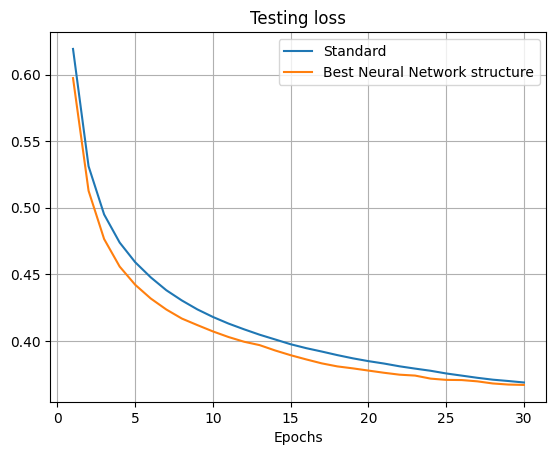

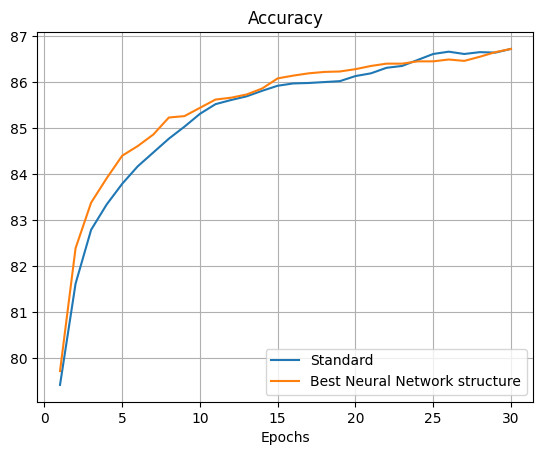

In [46]:
plot.plot_2_histories(
    std_test_loss_history, tun_test_loss_history, 'Testing loss', 'Standard', 'Best Neural Network structure')

plot.plot_2_histories(
    std_accuracy_history, tun_accuracy_history, 'Accuracy', 'Standard', 'Best Neural Network structure')